# EDA: Health Insurance Cross Sell Prediction

Explores the `customers` table in the project's MySQL/MariaDB database (loaded by `health_insurance_etl.ipynb`, browsable in DBeaver) to understand the target (`Response`) and how each feature relates to it, before any modeling. Data is loaded live from that database -- no CSV dependency.

## Instructions

1. Run `health_insurance_etl.ipynb` first so the `customers` table exists in `health_insurance_db` (XAMPP MySQL must be running).
2. Use the project's `.venv` kernel. Dependencies: `pip install -r app/requirements.txt`.
3. Run the cells from top to bottom and review the data-quality output before interpreting the charts.
4. Record findings in the conclusion at the end: the main data-quality issue, notable distributions or outliers, categories with different response rates, and limitations.

No CSV is read by this notebook; the MySQL table is the source of truth for the EDA. The analysis is descriptive and does not establish causation.


## Import libraries

In [3]:
# Environment check: makes sure this kernel has every package the notebook needs before anything else runs.
# If it fails, either pick the kernel "Health Insurance (.venv)" (top-right kernel picker) or install the
# missing packages into the selected Python:  python -m pip install -r ../app/requirements.txt
import importlib.util
import sys

required = {'pandas': 'pandas', 'numpy': 'numpy', 'sqlalchemy': 'SQLAlchemy', 'pymysql': 'PyMySQL',
            'sklearn': 'scikit-learn', 'matplotlib': 'matplotlib', 'seaborn': 'seaborn', 'scipy': 'scipy', 'joblib': 'joblib'}
missing = [pip_name for module, pip_name in required.items() if importlib.util.find_spec(module) is None]
if missing:
    raise ModuleNotFoundError(
        f'This kernel ({sys.executable}) is missing: {", ".join(missing)}. '
        'Fix: select the kernel "Health Insurance (.venv)" in the kernel picker (top-right), '
        f'or run:  "{sys.executable}" -m pip install {" ".join(missing)}'
    )
print(f'Environment OK: {sys.executable}')

Environment OK: c:\Users\acer\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns

pd.set_option('display.max_columns', None)

# One consistent, academic chart style for the whole notebook.
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'axes.labelsize': 11, 'axes.labelpad': 8,
    'xtick.labelsize': 10, 'ytick.labelsize': 10,
    'legend.fontsize': 10, 'legend.frameon': False,
    'axes.spines.top': False, 'axes.spines.right': False,
    'grid.alpha': 0.4, 'axes.axisbelow': True,
})
PRIMARY, ACCENT, NEUTRAL = '#3b6ea5', '#d1603d', '#9aa5b1'
thousands = FuncFormatter(lambda v, _: f'{v:,.0f}')


def fmt_p(p):
    """Readable p-value: values that underflow to 0.0 are reported as a bound, not as zero."""
    return 'p < 1e-300' if p == 0 else f'p = {p:.2g}'


def label_bars(ax, bars, labels, fontsize=9, offset=0.3):
    """Write one label above each bar, centred, without overlapping the bar."""
    for bar, text in zip(bars, labels):
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + offset, text,
                ha='center', va='bottom', fontsize=fontsize,
                bbox={'boxstyle': 'round,pad=0.15', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9})

## 1. Load data from the MySQL database

Data comes from the `customers` table in the local MySQL/MariaDB database (the same one `health_insurance_etl.ipynb` created and you can browse in DBeaver) -- no CSV file is read here.

**Before running the cell below:** make sure MySQL is started in the XAMPP Control Panel (Control Panel -> MySQL -> Start) and that `health_insurance_etl.ipynb` has been run at least once so the `customers` table exists and is populated.

The table's lowercase `snake_case` columns are renamed back to the original `Gender`/`Age`/... names, so the rest of this notebook is unchanged.

In [4]:
from sqlalchemy import create_engine

DB_HOST = 'localhost'
DB_PORT = 3306
DB_USER = 'root'
DB_PASSWORD = ''  # XAMPP default: empty password
DB_NAME = 'health_insurance_db'

engine = create_engine(f'mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}:{DB_PORT}/{DB_NAME}')

COLUMN_RENAME_MAP = {
    'gender': 'Gender', 'age': 'Age', 'driving_license': 'Driving_License',
    'region_code': 'Region_Code', 'previously_insured': 'Previously_Insured',
    'vehicle_age': 'Vehicle_Age', 'vehicle_damage': 'Vehicle_Damage',
    'annual_premium': 'Annual_Premium', 'policy_sales_channel': 'Policy_Sales_Channel',
    'vintage': 'Vintage', 'response': 'Response',
}

# This machine has ~1.5 GB of free RAM. pd.read_sql() without a chunksize calls
# cursor.fetchall(), which materialises all 381,109 rows as Python tuples before the
# DataFrame is built -- that peak is what raised MemoryError here on an earlier run.
# stream_results=True switches PyMySQL to an unbuffered (server-side) cursor and
# chunksize converts the rows in batches, so peak memory stays a few tens of MB.
def load_customers(engine, chunksize=50_000):
    """Read the whole customers table into a DataFrame without a large memory spike."""
    with engine.connect().execution_options(stream_results=True, max_row_buffer=chunksize) as conn:
        chunks = list(pd.read_sql('SELECT * FROM customers', con=conn, chunksize=chunksize))
    return pd.concat(chunks, ignore_index=True)


df = load_customers(engine).rename(columns=COLUMN_RENAME_MAP)
print(f'Shape: {df.shape}')
df.head()

Shape: (381109, 12)


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28,0,> 2 Years,Yes,40454.0,26,217,1
1,2,Male,76,1,3,0,1-2 Year,No,33536.0,26,183,0
2,3,Male,47,1,28,0,> 2 Years,Yes,38294.0,26,27,1
3,4,Male,21,1,11,1,< 1 Year,No,28619.0,152,203,0
4,5,Female,29,1,41,1,< 1 Year,No,27496.0,152,39,0


### Data dictionary: what each column contains

Every chart below refers to these columns, so the meaning of each value (especially the `0`/`1` codes) is fixed here once and reused as the axis and legend labels throughout the notebook.

| Column | Type | Values and meaning |
|---|---|---|
| `id` | identifier | Unique customer number. Identifies the row only; never used as a feature. |
| `Gender` | categorical | `Male` / `Female`. |
| `Age` | continuous (years) | 20 to 85. |
| `Driving_License` | binary flag | `0` = customer has **no** driving license, `1` = **has** a driving license. |
| `Region_Code` | category code | 0 to 52. An anonymised code for the customer's region. Numeric on disk, but the numbers are labels, not quantities (region 30 is not "more" than region 15). |
| `Previously_Insured` | binary flag | `0` = customer does **not** already have vehicle insurance, `1` = **already has** vehicle insurance. |
| `Vehicle_Age` | ordered categorical | `< 1 Year`, `1-2 Year`, `> 2 Years`. |
| `Vehicle_Damage` | categorical | `Yes` = the vehicle was damaged in the past, `No` = it was not. |
| `Annual_Premium` | continuous (currency) | Amount the customer pays per year for their health policy, 2,630 to 540,165. |
| `Policy_Sales_Channel` | category code | 1 to 163. An anonymised code for the outreach channel (agents, mail, phone, ...). Same caveat as `Region_Code`. |
| `Vintage` | continuous (days) | 10 to 299. Number of days the customer has been with the company. |
| `Response` | **target**, binary | `0` = customer is **not interested** in vehicle insurance, `1` = customer **is interested**. |

In [5]:
# Human-readable labels for every 0/1 column. Used for every axis, tick and legend below so
# no chart ever shows a bare "0" or "1".
RESPONSE_LABELS = {0: 'Not interested (0)', 1: 'Interested (1)'}
FLAG_LABELS = {
    'Driving_License': {0: 'No license (0)', 1: 'Has license (1)'},
    'Previously_Insured': {0: 'Not insured (0)', 1: 'Already insured (1)'},
}
CATEGORY_ORDER = {  # fixed, meaningful order for each categorical axis
    'Gender': ['Female', 'Male'],
    'Vehicle_Age': ['< 1 Year', '1-2 Year', '> 2 Years'],
    'Vehicle_Damage': ['No', 'Yes'],
    'Driving_License': ['No license (0)', 'Has license (1)'],
    'Previously_Insured': ['Not insured (0)', 'Already insured (1)'],
}
RESPONSE_COLORS = {'Not interested (0)': '#9aa5b1', 'Interested (1)': '#e4572e'}

# df_plot: a copy where the coded columns carry their labels, used only for plotting/tables.
df_plot = df.copy()
df_plot['Response_label'] = df_plot['Response'].map(RESPONSE_LABELS)
for col, labels in FLAG_LABELS.items():
    df_plot[col] = df_plot[col].map(labels)

OVERALL_RATE = df['Response'].mean() * 100
print(f'Overall response rate: {OVERALL_RATE:.2f}% of {len(df):,} customers are interested')

Overall response rate: 12.26% of 381,109 customers are interested


## 2. Data quality check

Basic sanity checks on the freshly-loaded table: missing values, duplicate rows, and dtypes. Worth re-checking here (rather than trusting the earlier ETL notebook) since this pull comes live from the database each time the notebook runs.

In [6]:
print('Shape:', df.shape)
print('\nDtypes:')
print(df.dtypes)
print('\nMissing values per column:')
print(df.isnull().sum())
print('\nFully duplicated rows:', df.duplicated().sum())

Shape: (381109, 12)

Dtypes:
id                        int64
Gender                      str
Age                       int64
Driving_License           int64
Region_Code               int64
Previously_Insured        int64
Vehicle_Age                 str
Vehicle_Damage              str
Annual_Premium          float64
Policy_Sales_Channel      int64
Vintage                   int64
Response                  int64
dtype: object

Missing values per column:
id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64

Fully duplicated rows: 0


**Result:** 0 missing values and 0 duplicate rows across all 381,109 records -- the dataset is clean, consistent with the original Kaggle CSV. No imputation or de-duplication is needed before proceeding. (If your `customers` table has since grown beyond this row count, re-run the cell above and check these numbers still hold -- they are not re-derived automatically from prose.)

## 3. Response analysis

`Response` is the target: 1 = customer is interested in the vehicle-insurance cross-sell, 0 = not.

**Variable type:** `Response` takes exactly two values (0/1) -- it is a **binary categorical** variable, not continuous. The right chart for the distribution of a binary/categorical variable is a **bar/count plot**, which shows the frequency of each discrete category. A line graph would be inappropriate here: a line implies a continuous, ordered progression between points (e.g. a trend over time), but there is no "between" 0 and 1 and no time axis -- connecting the two bars with a line would visually suggest a trend that does not exist in the data.

,meaning,customers,percent
Response,,,
0,Not interested (0),334399,87.74
1,Interested (1),46710,12.26


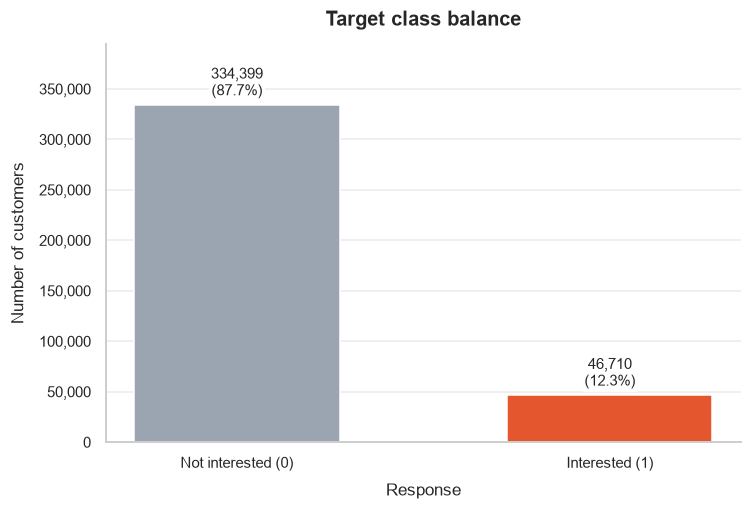

In [7]:
response_counts = df['Response'].value_counts().sort_index()
response_pct = df['Response'].value_counts(normalize=True).sort_index() * 100
summary = pd.DataFrame({
    'meaning': [RESPONSE_LABELS[k] for k in response_counts.index],
    'customers': response_counts.values,
    'percent': response_pct.round(2).values,
}, index=pd.Index(response_counts.index, name='Response'))
display(summary)

fig, ax = plt.subplots(figsize=(7, 4.8))
labels = [RESPONSE_LABELS[k] for k in response_counts.index]
bars = ax.bar(labels, response_counts.values, width=0.55, color=[RESPONSE_COLORS[l] for l in labels])
label_bars(ax, bars, [f'{n:,}\n({pct:.1f}%)' for n, pct in zip(response_counts.values, response_pct.values)],
           fontsize=10, offset=response_counts.max() * 0.015)
ax.set_title('Target class balance')
ax.set_xlabel('Response')
ax.set_ylabel('Number of customers')
ax.set_ylim(0, response_counts.max() * 1.18)
ax.yaxis.set_major_formatter(thousands)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.show()

**Reading the chart:** 334,399 customers (87.74%) are not interested versus 46,710 (12.26%) who are. This is a substantial **class imbalance** (roughly 7:1) -- a model that always predicts "not interested" would already score 87.74% accuracy while being useless for the actual business goal of finding interested customers. This directly shapes the modeling approach: accuracy is not a usable evaluation metric here, and the model notebook correctly uses ROC-AUC/PR-AUC plus `class_weight='balanced'` to compensate.

## 4. Numerical features

Numeric-dtype columns are split into two groups. **Continuous measurements** (`Age`, `Annual_Premium`, `Vintage`) are real quantities where averages, medians and distributions are meaningful. **Codes and flags** (`Region_Code`, `Policy_Sales_Channel`, `Driving_License`, `Previously_Insured`) are stored as numbers but are really category labels, so they are analysed as categories in section 6 instead; taking the mean of a region code would be meaningless.

In [8]:
numeric_dtype_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in ['id', 'Response']]

CODE_COLUMNS = {'Region_Code', 'Policy_Sales_Channel'}  # numeric dtype, but arbitrary category codes
continuous_features = [c for c in numeric_dtype_cols if df[c].nunique() > 20 and c not in CODE_COLUMNS]
coded_or_flag_features = [c for c in numeric_dtype_cols if c not in continuous_features]

print('Continuous numeric features:', continuous_features)
print('Coded / flag numeric features (treated as categorical in section 6):', coded_or_flag_features)

Continuous numeric features: ['Age', 'Annual_Premium', 'Vintage']
Coded / flag numeric features (treated as categorical in section 6): ['Driving_License', 'Region_Code', 'Previously_Insured', 'Policy_Sales_Channel']


### Descriptive statistics

For each continuous feature: how many values, the mean and median (if they differ a lot the distribution is skewed), the spread (standard deviation), and the minimum / quartiles / maximum.

In [9]:
desc = df[continuous_features].describe().T
desc.insert(2, 'median', df[continuous_features].median())
desc.columns = ['count', 'mean', 'median', 'std', 'min', '25%', '50%', '75%', 'max']
desc.round(1)

,count,mean,median,std,min,25%,50%,75%,max
Age,381109.0,38.8,36.0,15.5,20.0,25.0,36.0,49.0,85.0
Annual_Premium,381109.0,30564.4,31669.0,17213.2,2630.0,24405.0,31669.0,39400.0,540165.0
Vintage,381109.0,154.3,154.0,83.7,10.0,82.0,154.0,227.0,299.0


**Reading the table:** `Age` averages 38.8 years (median 36, so slightly more younger customers than older). `Annual_Premium` has a mean of 30,564 but a median of 31,669 and a maximum of 540,165; the huge maximum relative to the 75th percentile (39,400) already signals a long tail of very high premiums. `Vintage` runs almost uniformly from 10 to 299 days (mean 154.3 ≈ median 154), which suggests customers were sampled evenly across their tenure.

### How each continuous feature is distributed

One histogram per feature: the x-axis is the feature's value, the y-axis is how many customers fall in each bin. This shows the *shape* of each variable on its own, before relating it to `Response`.

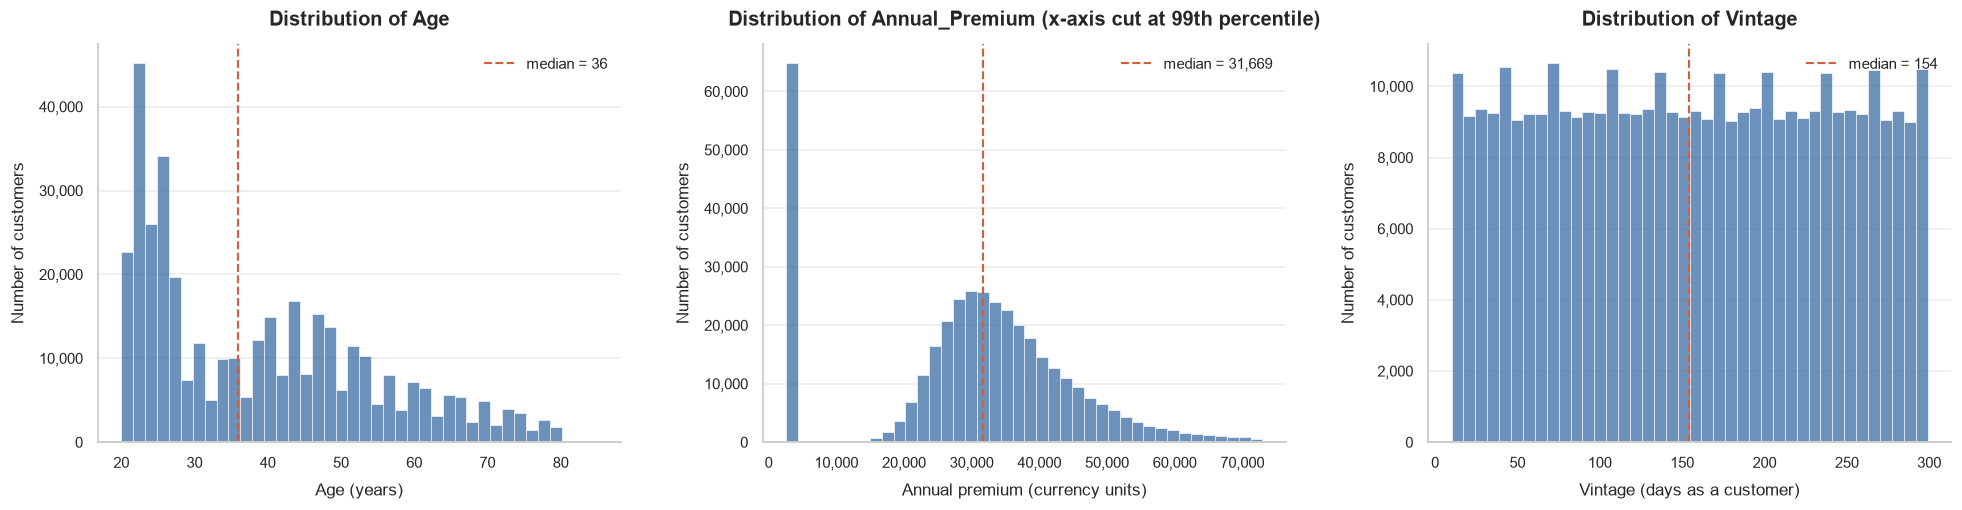

In [10]:
UNITS = {'Age': 'Age (years)', 'Annual_Premium': 'Annual premium (currency units)', 'Vintage': 'Vintage (days as a customer)'}

fig, axes = plt.subplots(1, len(continuous_features), figsize=(18, 4.8))
for ax, col in zip(axes, continuous_features):
    # Annual_Premium has a tail out to 540,165 that would squash the rest of the chart into a
    # sliver, so its x-axis is cut at the 99th percentile; the tail is covered by the boxplot below.
    upper = df[col].quantile(0.99) if col == 'Annual_Premium' else df[col].max()
    title_suffix = ' (x-axis cut at 99th percentile)' if col == 'Annual_Premium' else ''
    sns.histplot(data=df[df[col] <= upper], x=col, bins=40, color=PRIMARY, edgecolor='white', linewidth=0.4, ax=ax)
    ax.axvline(df[col].median(), color=ACCENT, linestyle='--', linewidth=1.4, label=f'median = {df[col].median():,.0f}')
    ax.set_title(f'Distribution of {col}{title_suffix}')
    ax.set_xlabel(UNITS[col])
    ax.set_ylabel('Number of customers')
    ax.yaxis.set_major_formatter(thousands)
    if col == 'Annual_Premium':
        ax.xaxis.set_major_formatter(thousands)
    ax.grid(axis='x', visible=False)
    ax.legend(loc='upper right')
plt.tight_layout(w_pad=3)
plt.show()

**Reading the histograms:**
- **Age** has a tall peak in the early 20s and then a long, gradually falling tail toward 85. Almost a third of all customers (114,505) are 25 or younger.
- **Annual_Premium** has two features worth noting: a tall spike at the far left (64,877 customers, 17%, all pay exactly 2,630, which looks like a fixed minimum-tier premium), then a bell-shaped bulk between roughly 20,000 and 45,000. The 1% of customers above the 99th percentile (up to 540,165) are cut from this chart so the bulk stays readable; they appear as the outlier dots in the boxplot in section 5.
- **Vintage** is nearly flat: every tenure length from 10 to 299 days has about the same number of customers. There is no natural peak, which is what we would expect if this feature carries no information about the customer.

## 5. Skewness and outliers (continuous features)

Skewness quantifies asymmetry (0 = symmetric, positive = long right tail). The IQR rule flags a value as an outlier if it falls more than 1.5x the interquartile range beyond the 25th/75th percentile, a standard, distribution-agnostic check.

In [11]:
outlier_rows = []
for col in continuous_features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = int(((df[col] < lo) | (df[col] > hi)).sum())
    outlier_rows.append({
        'feature': col,
        'skew': df[col].skew(),
        'iqr_lower_fence': lo,
        'iqr_upper_fence': hi,
        'n_outliers': n_out,
        'pct_outliers': round(100 * n_out / len(df), 2),
    })

outlier_summary = pd.DataFrame(outlier_rows)
outlier_summary

,feature,skew,iqr_lower_fence,iqr_upper_fence,n_outliers,pct_outliers
0,Age,0.672539,-11.0,85.0,0,0.00
1,Annual_Premium,1.766087,1912.5,61892.5,10320,2.71
2,Vintage,0.003030,-135.5,444.5,0,0.00


**Reading the table:** `Annual_Premium` is heavily right-skewed (skew ≈ 1.77) with 10,320 values (2.71%) beyond the IQR fences: a small number of customers pay very large premiums. Even so, its mean (30,564) sits *below* its median (31,669), because the 17% of customers paying exactly the 2,630 minimum pull the mean down more than the high tail pulls it up. Skewness and mean-vs-median disagree here, which is why the histogram and boxplot matter more than any single summary number. `Age` is mildly right-skewed (skew ≈ 0.67) with no IQR outliers; the age range (20-85) is simply not symmetric around its centre, not a data-quality problem. `Vintage` is essentially symmetric (skew ≈ 0.00) with no outliers. **Implication:** `Annual_Premium`'s skew and outliers favour rank-based statistical tests over tests that assume normality (see the statistical-analysis notebook). Tree/boosting models are naturally robust to this kind of skew, and the model notebook standardises it for the linear and KNN models, so no transformation is strictly required.

### Outlier check (boxplots)

Each box spans the 25th to 75th percentile, the line inside is the median, the whiskers reach the last value inside 1.5x IQR, and every dot beyond a whisker is an outlier by the rule above.

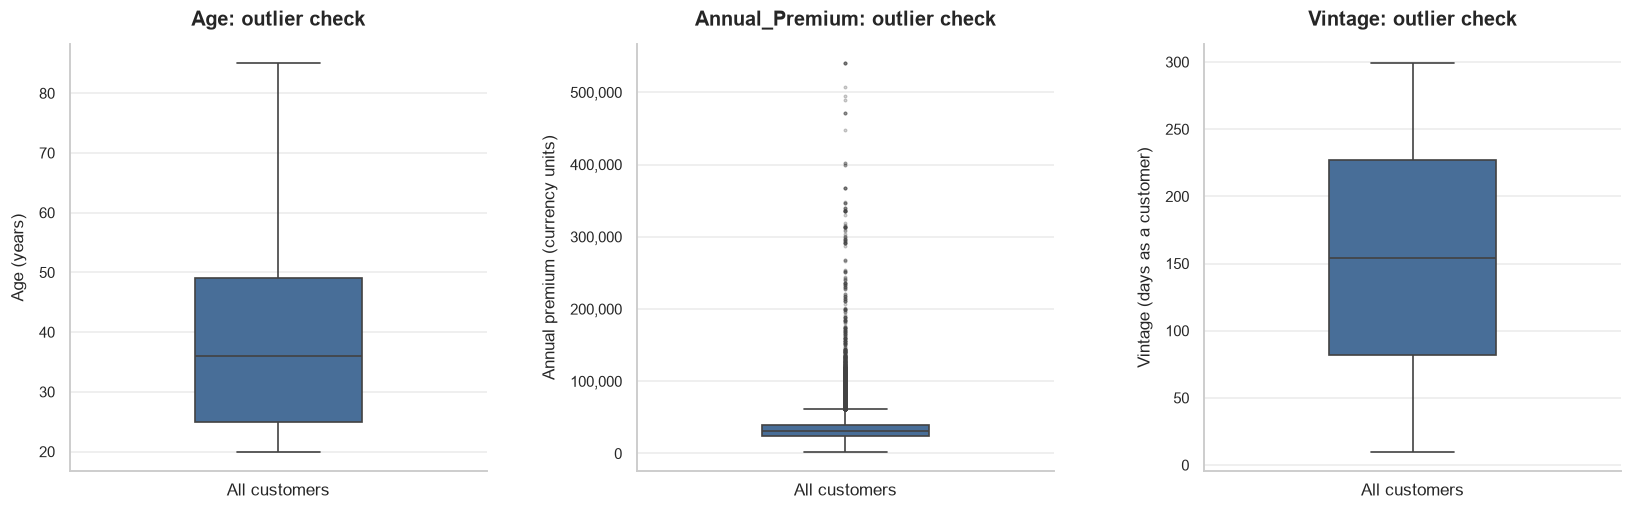

In [12]:
fig, axes = plt.subplots(1, len(continuous_features), figsize=(15, 4.8))
for ax, col in zip(axes, continuous_features):
    sns.boxplot(data=df, y=col, ax=ax, color=PRIMARY, width=0.4, linewidth=1.1,
                flierprops={'marker': '.', 'markersize': 3, 'alpha': 0.35})
    ax.set_title(f'{col}: outlier check')
    ax.set_ylabel(UNITS[col])
    ax.set_xlabel('All customers')
    ax.set_xticks([])
    ax.yaxis.set_major_formatter(thousands)
    ax.grid(axis='x', visible=False)
plt.tight_layout(w_pad=3)
plt.show()

**Reading the boxplots:** `Annual_Premium` shows a dense column of dots above the upper whisker, matching the 2.71% flagged by the IQR rule. These look like genuine high-premium customers rather than data-entry errors (the maximum, 540,165, is a plausible premium, not an impossible value), so they are kept rather than removed. `Age` and `Vintage` show no points beyond their whiskers, confirming they have no outliers by this rule.

### Response rate by value range

Instead of overlaying two density curves (which only shows *shape* and needs a legend to say which curve is which), each continuous feature is cut into ranges and the **percentage of customers in that range who are interested** is plotted. The dashed line is the overall rate (12.26%); a bar above it means that range responds more than average, below it less. The number of customers in each range is printed under the bar so a bar built on few customers is not over-read.

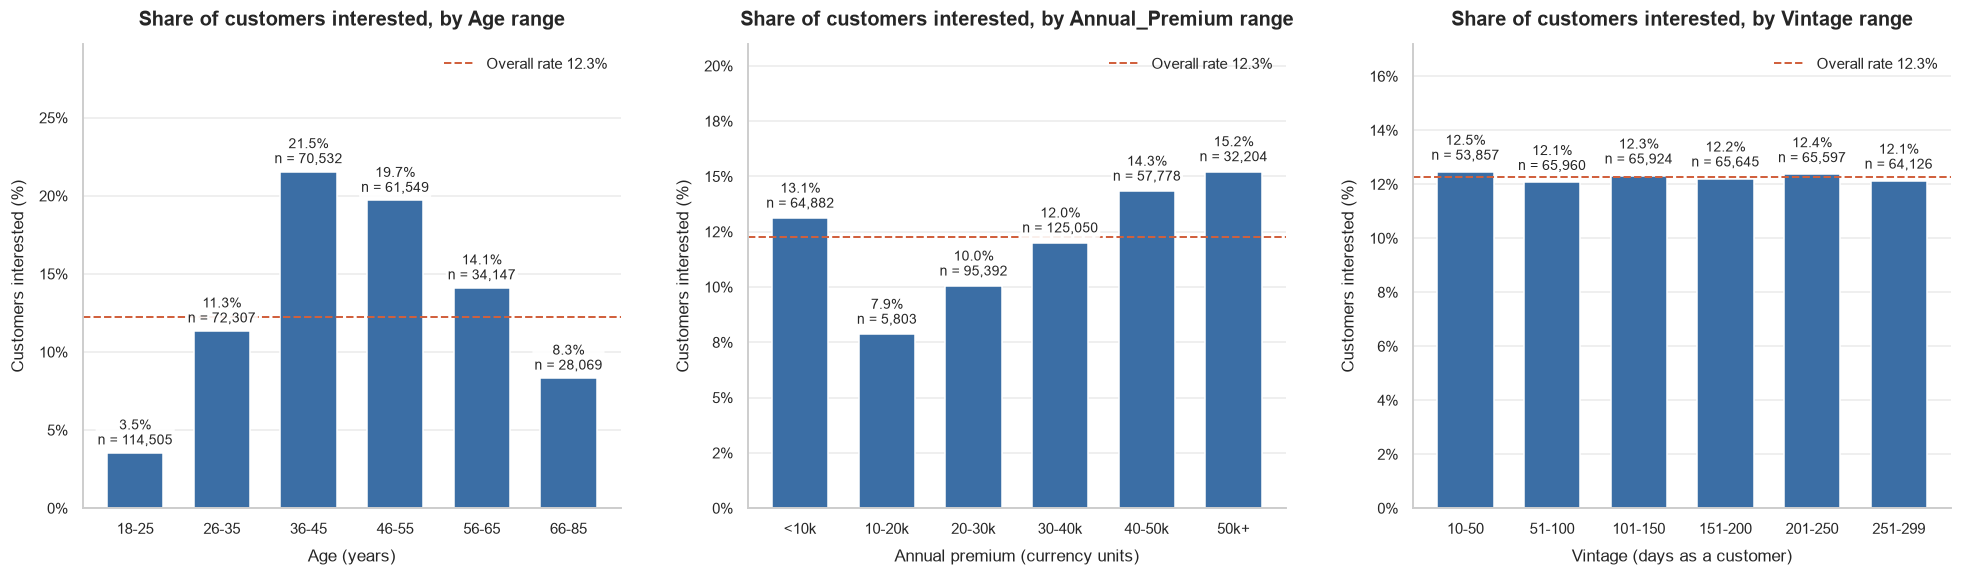


Age:


,customers,interested,response_rate_pct
Age,,,
18-25,114505,4047,3.53
26-35,72307,8198,11.34
36-45,70532,15192,21.54
46-55,61549,12123,19.70
56-65,34147,4815,14.10
66-85,28069,2335,8.32



Annual_Premium:


,customers,interested,response_rate_pct
Annual_Premium,,,
<10k,64882,8506,13.11
10-20k,5803,456,7.86
20-30k,95392,9575,10.04
30-40k,125050,14995,11.99
40-50k,57778,8279,14.33
50k+,32204,4899,15.21



Vintage:


,customers,interested,response_rate_pct
Vintage,,,
10-50,53857,6709,12.46
51-100,65960,7971,12.08
101-150,65924,8120,12.32
151-200,65645,8018,12.21
201-250,65597,8112,12.37
251-299,64126,7780,12.13


In [12]:
BINS = {
    'Age': dict(bins=[17, 25, 35, 45, 55, 65, 100], labels=['18-25', '26-35', '36-45', '46-55', '56-65', '66-85']),
    'Annual_Premium': dict(bins=[0, 10_000, 20_000, 30_000, 40_000, 50_000, 10_000_000], labels=['<10k', '10-20k', '20-30k', '30-40k', '40-50k', '50k+']),
    'Vintage': dict(bins=[0, 50, 100, 150, 200, 250, 300], labels=['10-50', '51-100', '101-150', '151-200', '201-250', '251-299']),
}

binned_tables = {}
fig, axes = plt.subplots(1, len(continuous_features), figsize=(18, 5.4))
for ax, col in zip(axes, continuous_features):
    ranges = pd.cut(df[col], bins=BINS[col]['bins'], labels=BINS[col]['labels'])
    table = df.groupby(ranges, observed=True)['Response'].agg(customers='count', interested='sum')
    table['response_rate_pct'] = (table['interested'] / table['customers'] * 100).round(2)
    binned_tables[col] = table

    bars = ax.bar(table.index.astype(str), table['response_rate_pct'], width=0.65, color=PRIMARY)
    ax.axhline(OVERALL_RATE, color=ACCENT, linestyle='--', linewidth=1.3, label=f'Overall rate {OVERALL_RATE:.1f}%')
    label_bars(ax, bars, [f'{rate:.1f}%\nn = {n:,}' for rate, n in zip(table['response_rate_pct'], table['customers'])], fontsize=9)
    ax.set_title(f'Share of customers interested, by {col} range')
    ax.set_xlabel(UNITS[col])
    ax.set_ylabel('Customers interested (%)')
    ax.set_ylim(0, max(table['response_rate_pct'].max(), OVERALL_RATE) * 1.38)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis='x', visible=False)
    ax.legend(loc='upper right')
plt.tight_layout(w_pad=3)
plt.show()

for col, table in binned_tables.items():
    print(f'\n{col}:')
    display(table)

**Reading the charts (one per feature):**
- **Age**: the strongest pattern of the three. Only 3.5% of customers aged 18-25 are interested, rising to a peak of 21.5% at 36-45 and 19.7% at 46-55, then falling again to 8.3% for 66-85. Interest in vehicle insurance is concentrated in middle-aged customers; the youngest group (which is also the largest, 114,505 customers) is the least interested.
- **Annual_Premium**: a mild upward trend. Customers paying under 10k respond at 13.1% (this is almost entirely the 2,630 minimum-premium group), the 10-20k band is the lowest at 7.9%, and the rate then climbs steadily from 10.0% (20-30k) to 15.2% (50k+). The differences are a few percentage points, far smaller than for `Age`.
- **Vintage**: every range sits between 12.1% and 12.5%, i.e. on top of the overall-rate line. How long someone has been a customer makes no difference to their interest.

### Averages within each Response group

The same relationship seen the other way round: the mean and median of each feature among customers who are **not interested** versus those who **are**. If the two rows differ, the feature separates the groups.

In [13]:
group_summary = df.groupby('Response')[continuous_features].agg(['mean', 'median']).round(1)
group_summary.index = group_summary.index.map(RESPONSE_LABELS)
group_summary.index.name = 'Response group'
display(group_summary)

corr_with_response = df[continuous_features + ['Response']].corr()['Response'].drop('Response').sort_values(key=abs, ascending=False)
print('Pearson correlation with Response (1 = interested):')
print(corr_with_response.round(4))

Age        Annual_Premium          Vintage       
                    mean median           mean   median    mean median
Response group                                                        
Not interested (0)  38.2   34.0        30419.2  31504.0   154.4  154.0
Interested (1)      43.4   43.0        31604.1  33002.0   154.1  154.0

Pearson correlation with Response (1 = interested):
Age               0.1111
Annual_Premium    0.0226
Vintage          -0.0011
Name: Response, dtype: float64


**Reading the table:** interested customers are on average **5 years older** (43.4 vs 38.2 years; medians 43 vs 34), pay a slightly higher premium (31,604 vs 30,419), and have identical tenure (154.1 vs 154.4 days). The correlations say the same thing in one number each: `Age` ≈ 0.11 (weak but real), `Annual_Premium` ≈ 0.02 (very weak), `Vintage` ≈ 0.00 (none). These patterns are formally tested with Mann-Whitney U in `stats_analysis_health_insurance.ipynb`.

## 6. Categorical features

Categorical features are the text columns (`Gender`, `Vehicle_Age`, `Vehicle_Damage`) plus the two 0/1 flags (`Driving_License`, `Previously_Insured`), which are categories stored as integers. From here on the flags are shown with their meaning (`No license (0)` / `Has license (1)`, `Not insured (0)` / `Already insured (1)`) rather than as bare numbers.

In [14]:
# pandas 3 gives text columns the new 'str' dtype, pandas 2 gives them 'object'; asking
# select_dtypes for both at once raises a Pandas4Warning, so select by "not numeric" instead.
categorical_dtype_cols = [c for c in df.columns if not pd.api.types.is_numeric_dtype(df[c])]
binary_flag_cols = [c for c in coded_or_flag_features if df[c].nunique() == 2]
categorical_features = categorical_dtype_cols + binary_flag_cols
print('Categorical features:', categorical_features)

Categorical features: ['Gender', 'Vehicle_Age', 'Vehicle_Damage', 'Driving_License', 'Previously_Insured']


### Counts and response rate per category

For each feature: how many customers fall in each category, how many of them are interested, and the response rate. These tables are the exact numbers behind the chart that follows.

In [15]:
category_tables = {}
for col in categorical_features:
    table = pd.crosstab(df_plot[col], df_plot['Response_label'])
    table = table.reindex(index=CATEGORY_ORDER[col], columns=list(RESPONSE_LABELS.values()))
    table['customers'] = table.sum(axis=1)
    table['share_of_all_customers_pct'] = (table['customers'] / len(df) * 100).round(2)
    table['response_rate_pct'] = (table['Interested (1)'] / table['customers'] * 100).round(2)
    category_tables[col] = table
    print(f'\n{col}:')
    display(table)


Gender:


Response_label,Not interested (0),Interested (1),customers,share_of_all_customers_pct,response_rate_pct
Gender,,,,,
Female,156835,18185,175020,45.92,10.39
Male,177564,28525,206089,54.08,13.84



Vehicle_Age:


Response_label,Not interested (0),Interested (1),customers,share_of_all_customers_pct,response_rate_pct
Vehicle_Age,,,,,
< 1 Year,157584,7202,164786,43.24,4.37
1-2 Year,165510,34806,200316,52.56,17.38
> 2 Years,11305,4702,16007,4.20,29.37



Vehicle_Damage:


Response_label,Not interested (0),Interested (1),customers,share_of_all_customers_pct,response_rate_pct
Vehicle_Damage,,,,,
No,187714,982,188696,49.51,0.52
Yes,146685,45728,192413,50.49,23.77



Driving_License:


Response_label,Not interested (0),Interested (1),customers,share_of_all_customers_pct,response_rate_pct
Driving_License,,,,,
No license (0),771,41,812,0.21,5.05
Has license (1),333628,46669,380297,99.79,12.27



Previously_Insured:


Response_label,Not interested (0),Interested (1),customers,share_of_all_customers_pct,response_rate_pct
Previously_Insured,,,,,
Not insured (0),159929,46552,206481,54.18,22.55
Already insured (1),174470,158,174628,45.82,0.09


### Response rate by category (chart)

One panel per feature. Bar height is the **percentage of customers in that category who are interested**; the dashed line is the overall 12.26%. The customer count under each bar shows how much data supports it.

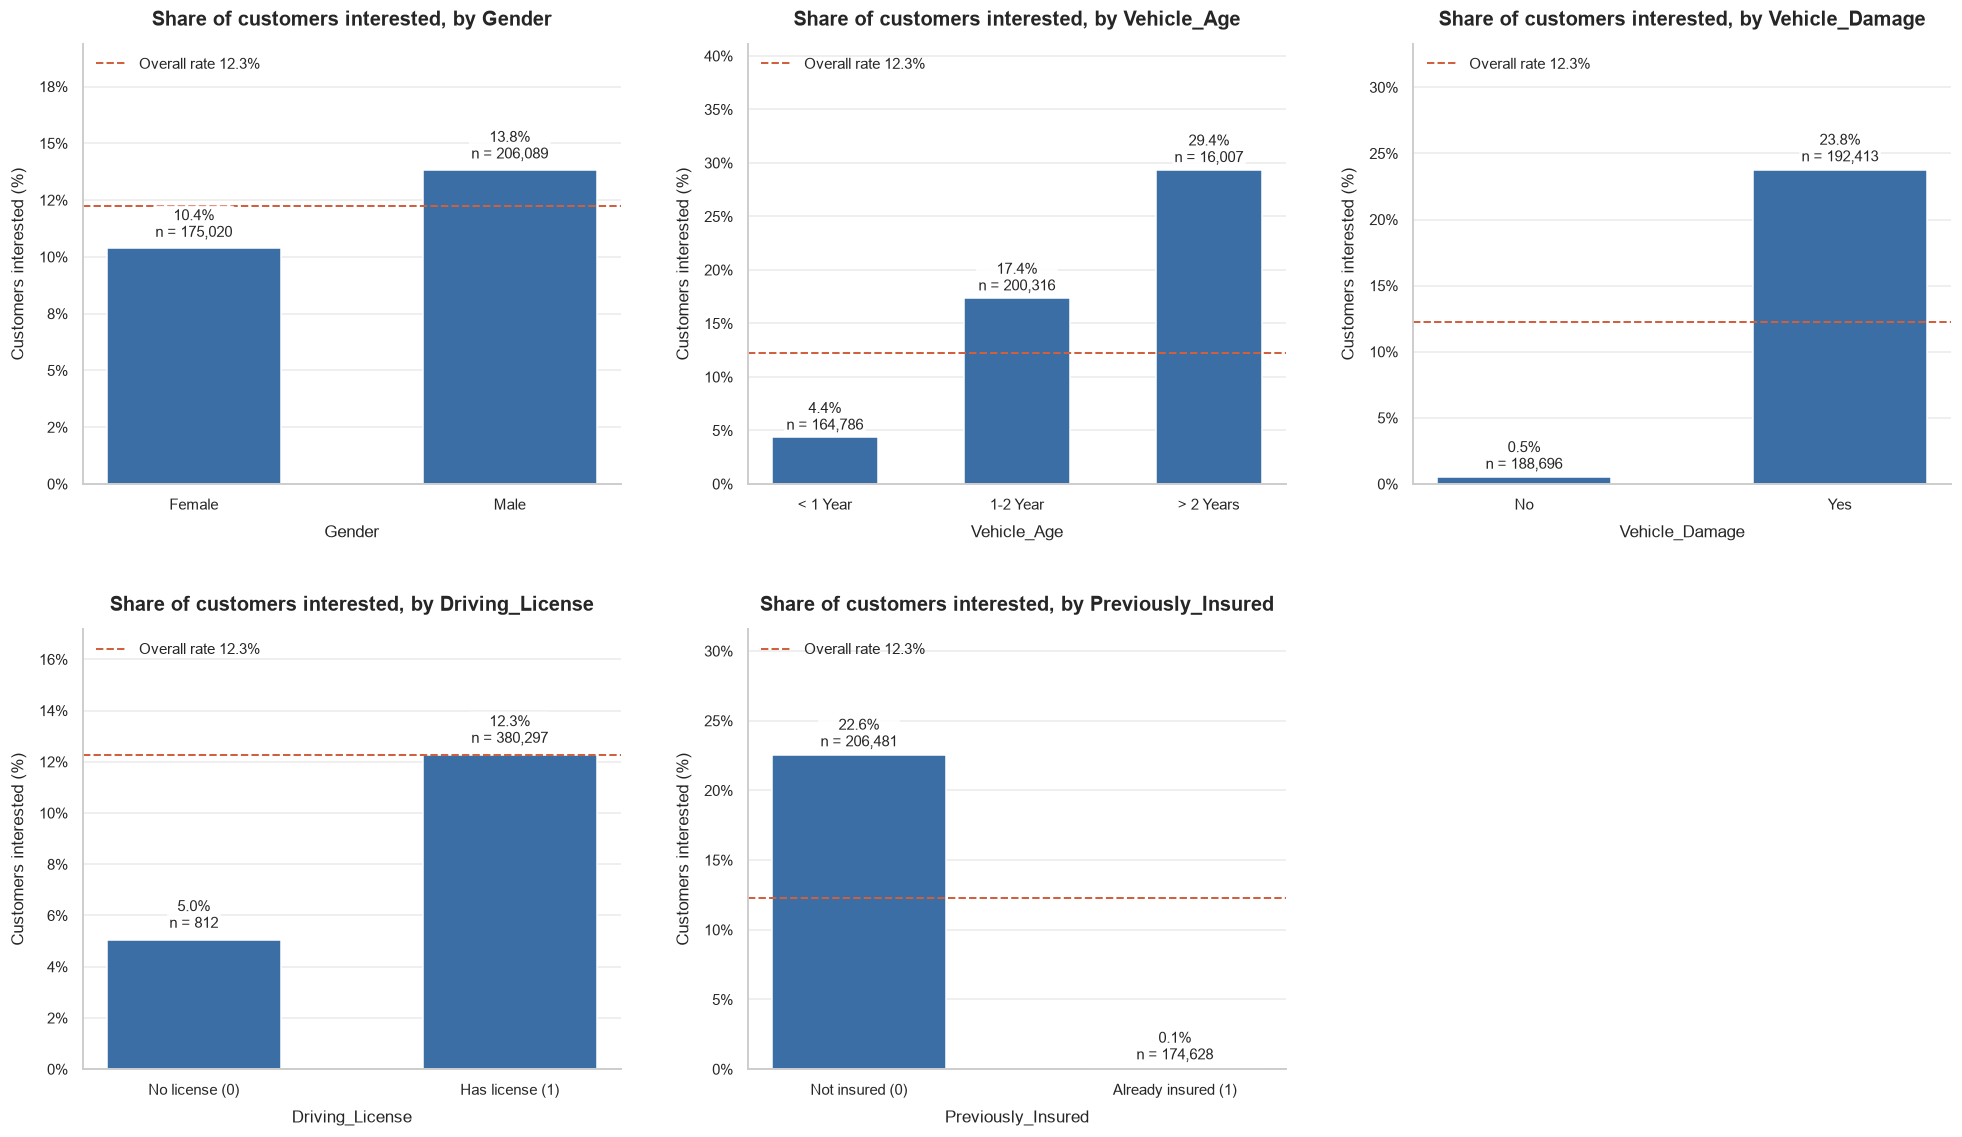

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10.5))
axes = axes.ravel()
for ax, col in zip(axes, categorical_features):
    table = category_tables[col]
    bars = ax.bar(table.index.astype(str), table['response_rate_pct'], width=0.55, color=PRIMARY)
    ax.axhline(OVERALL_RATE, color=ACCENT, linestyle='--', linewidth=1.3, label=f'Overall rate {OVERALL_RATE:.1f}%')
    label_bars(ax, bars, [f'{rate:.1f}%\nn = {n:,}' for rate, n in zip(table['response_rate_pct'], table['customers'])], fontsize=10)
    ax.set_title(f'Share of customers interested, by {col}')
    ax.set_xlabel(col)
    ax.set_ylabel('Customers interested (%)')
    ax.set_ylim(0, max(table['response_rate_pct'].max(), OVERALL_RATE) * 1.4)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis='x', visible=False)
    ax.legend(loc='upper left')
for ax in axes[len(categorical_features):]:
    ax.axis('off')
plt.tight_layout(w_pad=3, h_pad=3)
plt.show()

**Reading each panel:**
- **Gender**: men respond slightly more (13.8%) than women (10.4%). A real but small gap.
- **Vehicle_Age**: a clear ladder. Vehicles under 1 year: 4.4%. 1-2 years: 17.4%. Over 2 years: 29.4%. The older the vehicle, the more interest, though the `> 2 Years` group is small (16,007 customers).
- **Vehicle_Damage**: the biggest split in the whole dataset. Customers whose vehicle was damaged before respond at 23.8%; customers with no past damage respond at just 0.5% (982 of 188,696).
- **Driving_License**: almost everyone has a license (380,297 of 381,109). The 812 customers without one respond at 5.1% versus 12.3%, but the group is so tiny that this feature cannot matter much.
- **Previously_Insured**: the other decisive feature. Customers who are **not** already insured respond at 22.6%; customers who **already have** vehicle insurance respond at 0.09% (158 out of 174,628), which makes sense because they do not need the product.

These visual differences are tested formally (chi-square and Cramer's V) in the statistical-analysis notebook.

### How the two groups are composed (stacked view)

The same five features, but now each bar is a **Response group** and shows what share of that group falls in each category. This answers a different question: "of the customers who *are* interested, how many had vehicle damage?" rather than "of the customers with vehicle damage, how many are interested?".

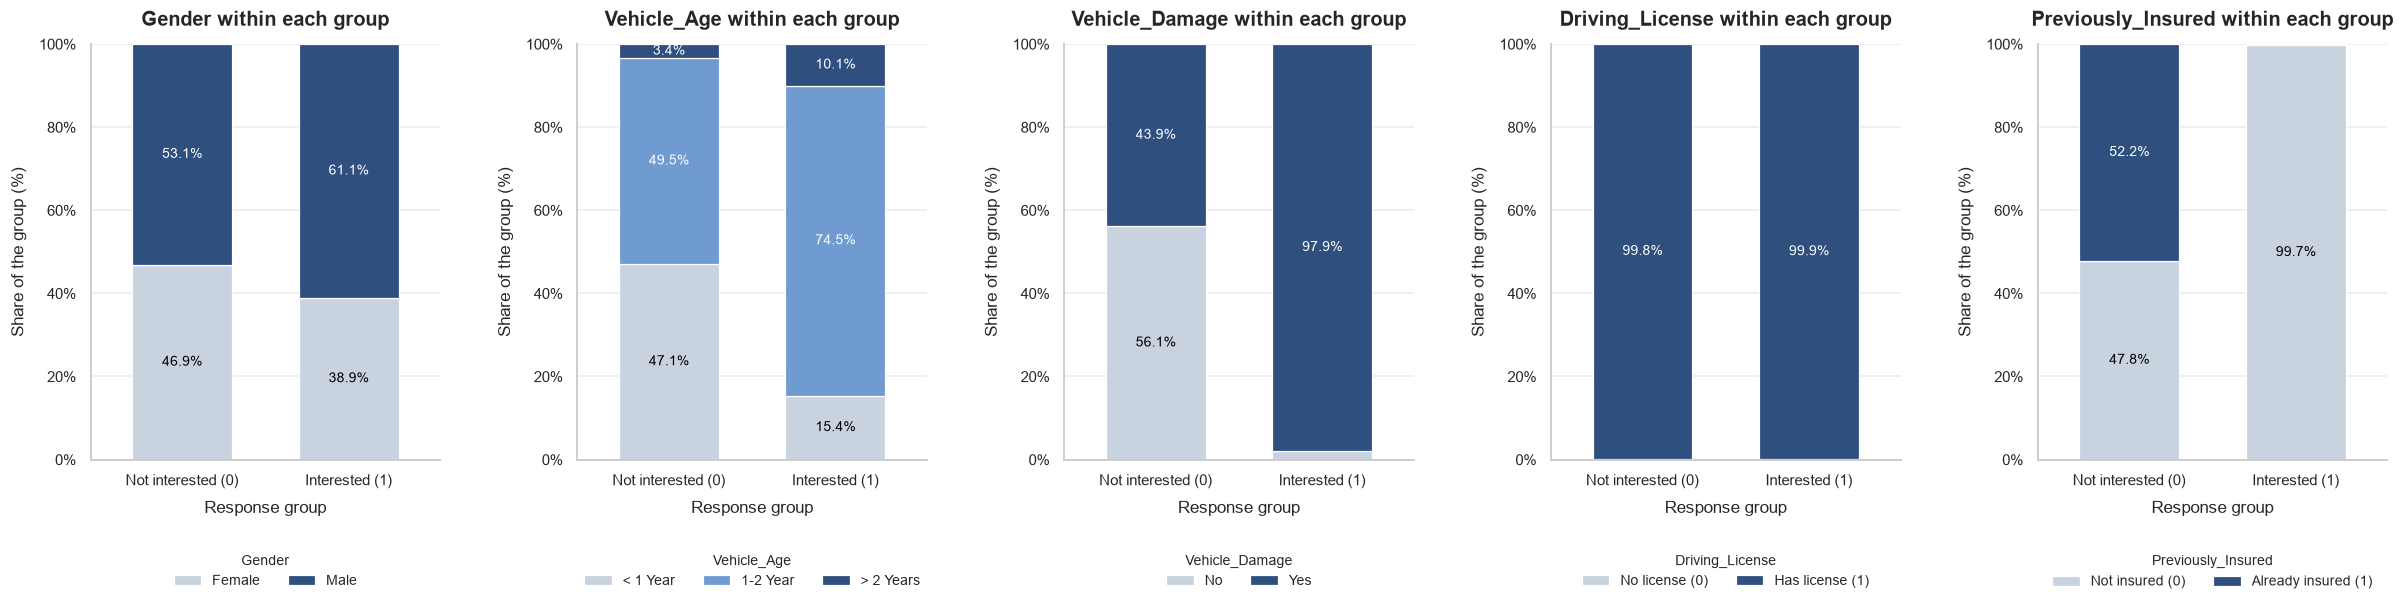

In [17]:
STACK_COLORS = {2: ['#c9d3df', '#2f4f7f'], 3: ['#c9d3df', '#6f9bd1', '#2f4f7f']}
DARK_COLORS = {'#2f4f7f', '#6f9bd1'}

fig, axes = plt.subplots(1, len(categorical_features), figsize=(22, 5.8))
for ax, col in zip(axes, categorical_features):
    composition = (
        pd.crosstab(df_plot['Response_label'], df_plot[col], normalize='index')
        .reindex(index=list(RESPONSE_LABELS.values()), columns=CATEGORY_ORDER[col]) * 100
    )
    colors = STACK_COLORS[len(CATEGORY_ORDER[col])]
    composition.plot(kind='bar', stacked=True, ax=ax, color=colors, edgecolor='white', linewidth=0.8, width=0.6)
    for container, color in zip(ax.containers, colors):
        labels = [f'{v:.1f}%' if v >= 3 else '' for v in container.datavalues]  # skip slivers
        ax.bar_label(container, labels=labels, label_type='center', fontsize=9,
                     color='white' if color in DARK_COLORS else 'black')
    ax.set_title(f'{col} within each group')
    ax.set_xlabel('Response group')
    ax.set_ylabel('Share of the group (%)')
    ax.set_ylim(0, 100)
    ax.yaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.tick_params(axis='x', rotation=0)
    ax.grid(axis='x', visible=False)
    ax.legend(title=col, fontsize=9, title_fontsize=9, loc='upper center', bbox_to_anchor=(0.5, -0.2),
              ncol=len(CATEGORY_ORDER[col]))
plt.tight_layout(w_pad=2.5)
plt.show()

**Reading the stacked bars:** among the **interested** customers, 97.9% had past vehicle damage and 99.7% were not previously insured, versus 43.9% and 47.8% among the not-interested group. In other words, an interested customer almost always looks like "uninsured vehicle with a damage history". Vehicle age follows the same direction (74.5% of interested customers have a 1-2 year vehicle, only 15.4% a sub-1-year one). Gender and driving license barely change between the two groups, which is why they are weak predictors.

### Region_Code and Policy_Sales_Channel

Both look numeric but are anonymised category codes with many levels (53 regions, 155 channels), so a single bar per level would be unreadable. Instead, the **ten most common codes** are shown with their response rate and customer count, so the biggest groups can be compared against the overall rate. Codes with fewer than 500 customers are not shown anywhere: a rate computed on a handful of people is not reliable.

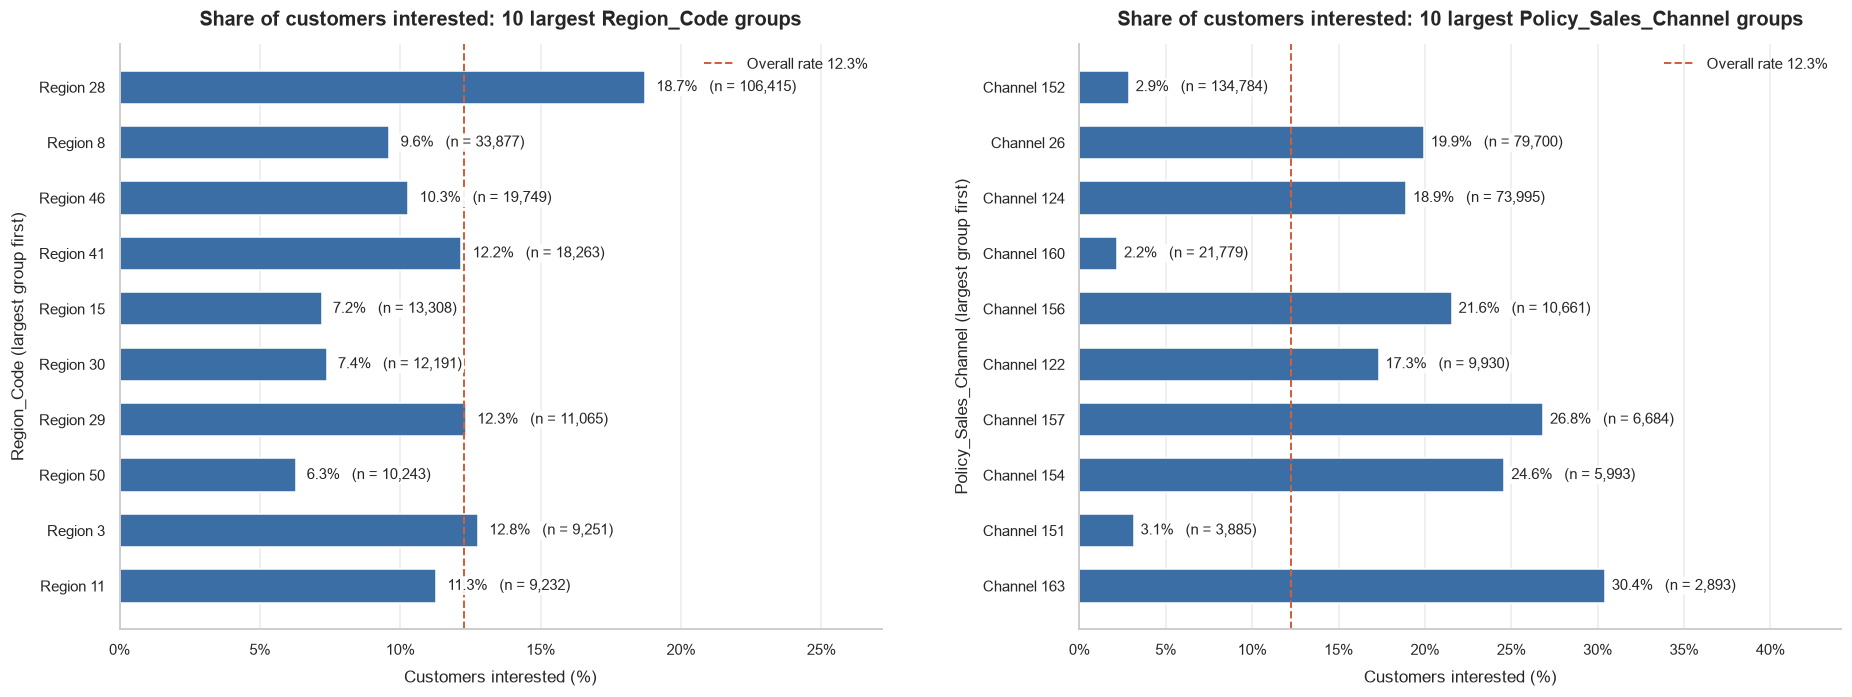


Region_Code: 53 distinct codes, 51 with at least 500 customers
Highest response rate (min 500 customers):


,customers,interested,response_rate_pct
Region_Code,,,
38,2026,389,19.20
28,106415,19917,18.72
19,1535,250,16.29
4,1801,285,15.82
23,1960,300,15.31


Lowest response rate (min 500 customers):


,customers,interested,response_rate_pct
Region_Code,,,
44,808,33,4.08
25,2503,107,4.27
10,4374,263,6.01
50,10243,642,6.27
22,1309,83,6.34



Policy_Sales_Channel: 155 distinct codes, 34 with at least 500 customers
Highest response rate (min 500 customers):


,customers,interested,response_rate_pct
Policy_Sales_Channel,,,
155,1234,395,32.01
163,2893,880,30.42
3,523,159,30.40
157,6684,1794,26.84
31,631,160,25.36


Lowest response rate (min 500 customers):


,customers,interested,response_rate_pct
Policy_Sales_Channel,,,
160,21779,475,2.18
152,134784,3858,2.86
151,3885,122,3.14
1,1074,35,3.26
153,607,36,5.93


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
code_tables = {}
for ax, col in zip(axes, ['Region_Code', 'Policy_Sales_Channel']):
    stats_by_code = df.groupby(col)['Response'].agg(customers='count', interested='sum')
    stats_by_code['response_rate_pct'] = (stats_by_code['interested'] / stats_by_code['customers'] * 100).round(2)
    top = stats_by_code.sort_values('customers', ascending=False).head(10)
    code_tables[col] = stats_by_code

    label_prefix = 'Region' if col == 'Region_Code' else 'Channel'
    y_labels = [f'{label_prefix} {int(c)}' for c in top.index]
    bars = ax.barh(y_labels, top['response_rate_pct'], height=0.6, color=PRIMARY)
    ax.invert_yaxis()  # largest group at the top
    ax.axvline(OVERALL_RATE, color=ACCENT, linestyle='--', linewidth=1.3, label=f'Overall rate {OVERALL_RATE:.1f}%')
    for bar, rate, n in zip(bars, top['response_rate_pct'], top['customers']):
        ax.text(bar.get_width() + 0.4, bar.get_y() + bar.get_height() / 2,
                f'{rate:.1f}%   (n = {n:,})', va='center', fontsize=9.5,
                bbox={'boxstyle': 'round,pad=0.15', 'facecolor': 'white', 'edgecolor': 'none', 'alpha': 0.9})
    ax.set_title(f'Share of customers interested: 10 largest {col} groups')
    ax.set_xlabel('Customers interested (%)')
    ax.set_ylabel(f'{col} (largest group first)')
    ax.set_xlim(0, max(top['response_rate_pct'].max(), OVERALL_RATE) * 1.45)
    ax.xaxis.set_major_formatter(PercentFormatter(decimals=0))
    ax.grid(axis='y', visible=False)
    ax.legend(loc='upper right')
plt.tight_layout(w_pad=4)
plt.show()

for col, stats_by_code in code_tables.items():
    reliable = stats_by_code[stats_by_code['customers'] >= 500]
    print(f'\n{col}: {stats_by_code.shape[0]} distinct codes, {reliable.shape[0]} with at least 500 customers')
    print('Highest response rate (min 500 customers):')
    display(reliable.sort_values('response_rate_pct', ascending=False).head(5))
    print('Lowest response rate (min 500 customers):')
    display(reliable.sort_values('response_rate_pct').head(5))

**Reading the charts:**
- **Region_Code**: region 28 alone holds 106,415 customers (28% of the data) and responds well above average at 18.7%. The other big regions sit between 6.3% (region 50) and 12.8% (region 3). The region does carry some signal, but modestly.
- **Policy_Sales_Channel**: much sharper differences. Channel 152, the single largest with 134,784 customers, converts at only 2.9%, and channel 160 at 2.2%. Channels 26 and 124 (79,700 and 73,995 customers) convert at 19.9% and 18.9%, and smaller channels 157 and 163 reach 26.8% and 30.4%. Which channel reached a customer is strongly related to whether they respond, which is why this code is one of the model's more useful inputs despite being "just a number".

**How the model notebook uses these codes.** One-hot encoding 53 regions and 155 channels would add ~200 sparse columns, so the model notebook uses two other representations. Tree models get the raw code and split on ranges of it, which works here because the large channels happen to cluster (152/160 low, 26/124 high), even though the numbers have no real order. Linear Regression, Logistic Regression and KNN get the code **target-encoded**: replaced by that code's response rate, i.e. exactly the per-code rates shown above, computed with cross-fitting so a row never sees its own label. Note that the two largest channels have similar frequencies but opposite response rates (152: 35% of customers, 2.9%; 26: 21%, 19.9%), so encoding them by how *common* they are would throw this signal away.

## 7. Correlation heatmap (numeric columns)

Pairwise Pearson correlations between every numeric-dtype column and `Response`. The colour scale runs from blue (negative, -1) through white (0) to red (positive, +1). For the 0/1 columns the sign has a fixed meaning, stated in the tick labels: e.g. a negative correlation between `Previously_Insured (1 = insured)` and `Response (1 = interested)` means insured customers are *less* interested. Correlations with the two category codes are included for completeness but should be read with caution, since the code numbers have no natural order.

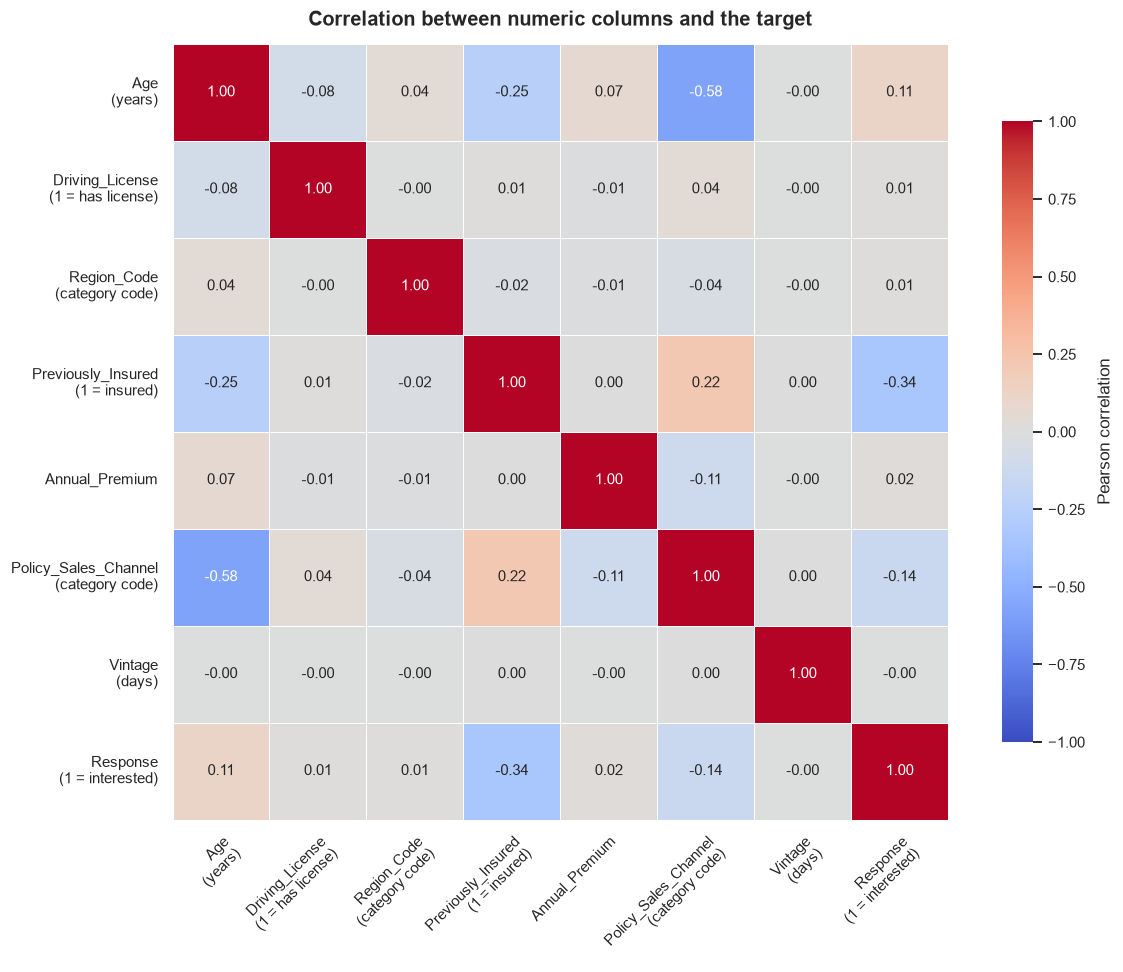

In [19]:
numeric_for_corr = numeric_dtype_cols + ['Response']
corr = df[numeric_for_corr].corr()

TICK_LABELS = {
    'Age': 'Age\n(years)',
    'Driving_License': 'Driving_License\n(1 = has license)',
    'Region_Code': 'Region_Code\n(category code)',
    'Previously_Insured': 'Previously_Insured\n(1 = insured)',
    'Annual_Premium': 'Annual_Premium',
    'Policy_Sales_Channel': 'Policy_Sales_Channel\n(category code)',
    'Vintage': 'Vintage\n(days)',
    'Response': 'Response\n(1 = interested)',
}
corr_labeled = corr.rename(index=TICK_LABELS, columns=TICK_LABELS)

fig, ax = plt.subplots(figsize=(11.5, 9))
sns.heatmap(corr_labeled, annot=True, fmt='.2f', annot_kws={'size': 10}, cmap='coolwarm', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.6, linecolor='white', ax=ax,
            cbar_kws={'label': 'Pearson correlation', 'shrink': 0.8})
ax.set_title('Correlation between numeric columns and the target')
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', rotation=45, labelsize=9.5)
ax.tick_params(axis='y', rotation=0, labelsize=9.5)
plt.setp(ax.get_xticklabels(), ha='right', rotation_mode='anchor')
plt.tight_layout()
plt.show()

**Reading the heatmap (bottom row / right column = correlation with the target):**
- `Previously_Insured` ≈ **-0.34**: the strongest single relationship, and negative, i.e. already-insured customers are far less likely to be interested. Matches the 22.6% vs 0.09% split in section 6.
- `Policy_Sales_Channel` ≈ -0.14 and `Age` ≈ +0.11: moderate-to-weak. The channel correlation is negative only because the large low-converting channels happen to have high code numbers (152, 160); it is an artefact of the labelling, not a real "higher channel number, lower interest" rule.
- `Annual_Premium` ≈ 0.02, `Driving_License` ≈ 0.01, `Region_Code` ≈ 0.01, `Vintage` ≈ 0.00: essentially no linear relationship.

**Between predictors:** the only notable pair is `Age` and `Policy_Sales_Channel` at **-0.58** (younger customers were reached through the high-numbered channels), plus `Age` and `Previously_Insured` at -0.25 (younger customers are more often already insured). Neither is severe enough to drop a feature, but the `Age`/`Policy_Sales_Channel` pair is worth remembering if a linear model is used; it is checked formally in the statistical-analysis notebook.

## 8. EDA conclusion

**Class imbalance.** `Response` is heavily imbalanced: 334,399 customers (87.74%) are not interested vs. 46,710 (12.26%) interested, about 7:1. Accuracy is not a meaningful evaluation metric; ROC-AUC/PR-AUC and class weighting or threshold tuning (used in the model notebook) are the right approach.

**Numerical patterns.** `Age` is the only continuous feature with a clear relationship to `Response`: interest is lowest for 18-25 year-olds (3.5%), peaks at 36-45 (21.5%), and falls again past 65; interested customers are on average 5 years older. `Annual_Premium` shows only a mild upward trend (7.9% to 15.2% across premium bands) and is right-skewed with 2.71% IQR outliers that are genuine high-premium customers, not errors. `Vintage` shows no relationship at all (every tenure band sits at 12.1-12.5%).

**Categorical patterns.** `Vehicle_Damage` (23.8% vs 0.5%) and `Previously_Insured` (22.6% vs 0.09%) are by far the strongest splits: an interested customer almost always has an uninsured vehicle with a damage history. `Vehicle_Age` is a clean ladder (4.4% → 17.4% → 29.4%). `Policy_Sales_Channel` matters a lot despite being a code (channel 152: 2.9%; channels 26/124: ~19%; channel 163: 30.4%). `Gender` (10.4% vs 13.8%), `Region_Code` and especially `Driving_License` (only 812 customers lack one) are weak.

**Data quality.** 0 missing values and 0 duplicate rows across all 381,109 records (the ETL notebook also confirmed every `id` is unique); no cleaning is required before modelling. The one oddity is the 64,877 customers (17%) who all pay exactly 2,630, which looks like a fixed minimum-tier premium rather than an error.

**Implications for modelling.** (1) Handle class imbalance explicitly. (2) `Previously_Insured`, `Vehicle_Damage`, `Vehicle_Age`, `Policy_Sales_Channel` and `Age` are the most useful predictors; `Vintage` can be expected to contribute nothing. (3) Don't one-hot encode `Region_Code`/`Policy_Sales_Channel`: pass the raw code to tree models and target-encode it (per-code response rate) for linear and distance-based models, since their per-code response rates are where the signal is. (4) The moderate `Age`/`Policy_Sales_Channel` correlation (-0.58) is between `Age` and the raw code numbers, so it says little about the target-encoded version the linear models actually see. Formal significance testing of all of the above is in `stats_analysis_health_insurance.ipynb`.